# 05d — Compare fixed pipelines, verify extraction, and freeze the path

**Phase 4 · Validation comparison and reusable inference workshop**

We now have an adapted Donut model. The questions change: does its saved model
reproduce the selected answers, does the reusable source preserve the research
behavior, where do OCR and Donut differ, and what does each complete request cost?

The [comparison report](../docs/experiments/ocr-donut-comparison.md) owns measured
results; [Donut usage](../docs/guides/donut-usage.md) explains the public API; the
[phase record](../docs/phases/phase-4.md) owns delivery and its limitations.

## How to execute this workshop

Use the repository `.venv`, restore the frozen artifact directories, and Run All:

```bash
.venv/bin/python -m experiments.execute_phase4_notebook 05d_donut_evaluation
```

This notebook actively audits the real retained comparison, recomputes scores,
plots outcomes/failures, and executes one GPU and one CPU request through the
frozen public API. The six-block timing study was actually executed separately
so plotting and notebook work could not contend with its measured requests.
To reproduce that complete study in a new evidence directory:

```bash
.venv/bin/python -m experiments.compare_ocr_donut
```

Do not run other research GPU jobs concurrently with the timing study. No test
identity is needed here, and training features must not enter inference timing.

In [1]:
from pathlib import Path
import gc, json, inspect
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

here=Path.cwd().resolve()
ROOT=next(p for p in [here,*here.parents] if (p/'PROJECT.md').is_file())
from experiments.donut_workshop import read_json, write_json, new_run, setup, sha, load_observations
from experiments.donut_protocol import parse_sequence as research_parse, serialize_fields as research_serialize
from kyc_router.serialization import parse_sequence, serialize_fields
from kyc_router.donut import load_donut_pipeline
from kyc_router.evaluation import score_document, summarize_scores
from kyc_router.geometry import crop_field
setup()
REVIEW=new_run('phase4_evaluation_review')
COMPARISON=ROOT/'outputs/phase4_comparison/20261015T124404754152Z'
completion=read_json(COMPARISON/'completion.json')
policy=read_json(COMPARISON/'policy.json')
manifest=read_json(ROOT/'configs/donut_pipeline_v1.json')
assert completion['status']=='completed' and completion['test_evaluated'] is False
assert sha(ROOT/'configs/ocr_donut_comparison_v1.json')==completion['policy_sha256']
print('Comparison:',COMPARISON.relative_to(ROOT))
print('Review artifacts:',REVIEW.relative_to(ROOT))

/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Comparison: outputs/phase4_comparison/20261015T124404754152Z
Review artifacts: outputs/phase4_evaluation_review/20261015T124934943868Z


## 1. Verify equal inputs and retained denominators

The experiment uses the same 30 canonical pixel arrays for both pipelines:
15 validation identities, each with template and photo views. Both use the seven
required fields, float32, and the same normalization/scoring code. OCR receives
known field rectangles; Donut receives the whole image. This compares the two
declared pipelines, not image encoders in isolation.

Re-score retained raw predictions using the shared scorer. The comparison's
`truth` values are normalized targets; the training review also replays original
annotation references and verifies the same normalized metrics. Raw whitespace
and formatting differences are preserved, not treated as recognition fixes.

In [2]:
observations=load_observations(splits=('validation',))
obs_index={(o['identity_key'],o['source']):o for o in observations}
predictions={kind:read_json(COMPARISON/f'{kind}_predictions.json') for kind in ['ocr','donut']}
accuracy=[];field_tables=[]
for kind,records in predictions.items():
    fs=[];ds=[]
    for record in records:
        key=(record['identity_key'],record['source'])
        obs=obs_index[key]
        assert record['pixel_sha256']==obs['pixel_sha256']
        fields,doc=score_document(obs['truth_raw'],record['raw_fields'])
        metadata={'identity_key':key[0],'source':key[1]}
        fs.extend([{**metadata,**f} for f in fields]);ds.append({**metadata,**doc})
    assert len(fs)==210 and len(ds)==30
    per_field,summary=summarize_scores(pd.DataFrame(fs),pd.DataFrame(ds))
    for row in summary.to_dict(orient='records'):
        accuracy.append({'pipeline':kind,**row})
    field_tables.append(per_field.assign(pipeline=kind))
accuracy=pd.DataFrame(accuracy);per_field=pd.concat(field_tables,ignore_index=True)
display(accuracy[['pipeline','source','normalized_matches','field_samples','macro_field_em','edit_distance','reference_characters','cer','document_matches','documents','schema_failures']])
assert accuracy.groupby('pipeline').normalized_matches.sum().to_dict()=={'donut':193,'ocr':194}

,pipeline,source,normalized_matches,field_samples,macro_field_em,edit_distance,reference_characters,cer,document_matches,documents,schema_failures
0,ocr,photo,96,105,0.914286,17,911,0.018661,8,15,0
1,ocr,template,98,105,0.933333,11,911,0.012075,9,15,0
2,donut,photo,94,105,0.895238,11,911,0.012075,6,15,0
3,donut,template,99,105,0.942857,6,911,0.006586,10,15,0


## 2. See field differences rather than relying on one aggregate

Macro Field EM gives each field equal weight. With seven fields present in every
view, it equals total correct fields divided by 210. Document EM is stricter:
every field must be correct together. CER measures character edits and can improve
even when fewer entire fields match.

**Predict:** can Donut have lower CER but slightly lower Field EM than OCR?
Compare the denominators and inspect the errors before calling either model better.

pipeline                  donut  ocr
source   field                      
photo    date_of_birth       15   14
         document_number     13   13
         expiry_date         15   15
         given_names          9   13
         nationality         15   15
         sex                 15   15
         surname             12   11
template date_of_birth       15   15
         document_number     14   14
         expiry_date         15   15
         given_names         12   13
         nationality         15   15
         sex                 15   15
         surname             13   11

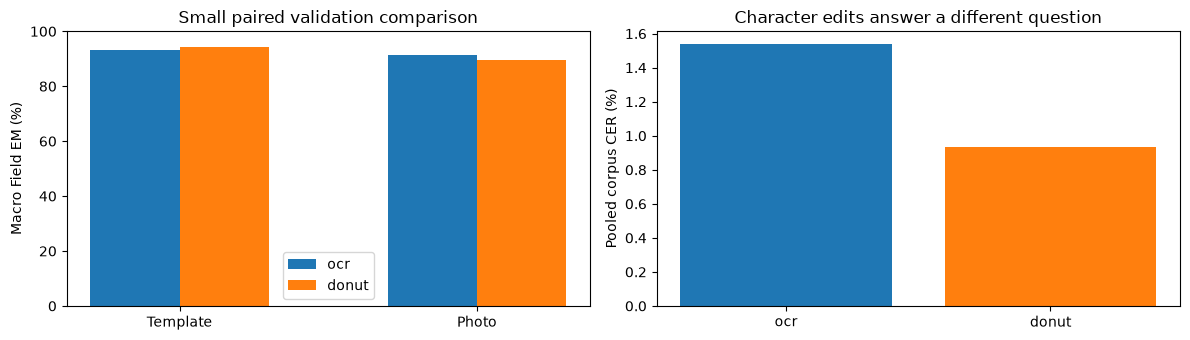

In [3]:
display(per_field.pivot(index=['source','field'],columns='pipeline',values='normalized_matches'))
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for i,kind in enumerate(['ocr','donut']):
    group=accuracy.loc[accuracy.pipeline.eq(kind)].set_index('source')
    axes[0].bar(np.arange(2)+(i-.5)*.3,[group.loc[s,'macro_field_em']*100 for s in ['template','photo']],width=.3,label=kind)
axes[0].set(xticks=[0,1],xticklabels=['Template','Photo'],ylim=(0,100),ylabel='Macro Field EM (%)',title='Small paired validation comparison')
axes[0].legend()
for kind in ['ocr','donut']:
    group=accuracy.loc[accuracy.pipeline.eq(kind)]
    axes[1].bar(kind,group.edit_distance.sum()/group.reference_characters.sum()*100)
axes[1].set(ylabel='Pooled corpus CER (%)',title='Character edits answer a different question')
fig.tight_layout();fig.savefig(REVIEW/'accuracy_comparison.png',bbox_inches='tight');plt.show()

### 2.1 Complementarity is a development diagnostic here

The four-way table below counts individual fields, not route decisions or fully
correct documents. It can reveal different errors but does not show that an
image-quality router can predict which model to choose. The full degradation
benchmark, document-level oracle, and learned routing remain later phases.

In [4]:
pair=pd.read_csv(COMPARISON/'paired_fields.csv')
complement=completion['field_complementarity_development_only']
assert sum(complement.values())==210
display(pd.Series(complement,name='paired required fields').to_frame())
errors=pair.loc[~pair.normalized_exact_match_donut]
print('Donut errors by field:',errors.field.value_counts().to_dict())
display(errors[['identity_key','source','field','normalized_ground_truth_donut','raw_prediction_donut','normalized_prediction_donut','prediction_is_valid_donut']])
print('Wrong Donut fields that pass semantic validation:',int(errors.prediction_is_valid_donut.sum()),'/',len(errors))

,paired required fields
both_correct,181
ocr_only,13
donut_only,12
both_wrong,4


Donut errors by field: {'given_names': 9, 'surname': 5, 'document_number': 3}


,identity_key,source,field,normalized_ground_truth_donut,raw_prediction_donut,normalized_prediction_donut,prediction_is_valid_donut
44,alb_id/12,template,given_names,aleksander,Aleksandr,aleksandr,True
51,alb_id/12,photo,given_names,aleksander,alekssander,alekssander,True
64,alb_id/14,photo,surname,bajrami,bajram,bajram,True
93,alb_id/30,photo,given_names,ardi,ardii,ardii,True
107,alb_id/32,photo,given_names,ardit,ardita,ardita,True
114,alb_id/36,template,given_names,arbërie,arberie,arberie,True
121,alb_id/36,photo,given_names,arbërie,arberie,arberie,True
127,alb_id/50,template,surname,corbajram,carbajram,carbajram,True
128,alb_id/50,template,given_names,astrit,astri,astri,True
134,alb_id/50,photo,surname,corbajram,carbajram,carbajram,True


Wrong Donut fields that pass semantic validation: 15 / 17


### 2.2 Inspect pixels behind representative disagreements

These crops are diagnostic displays only. The measured Donut request consumed
the whole card. Use known geometry to inspect one OCR-only, one Donut-only, and
one both-wrong field. Compare diacritics, character shapes, and the printed
reference; do not invent post-selection corrections from this gallery.

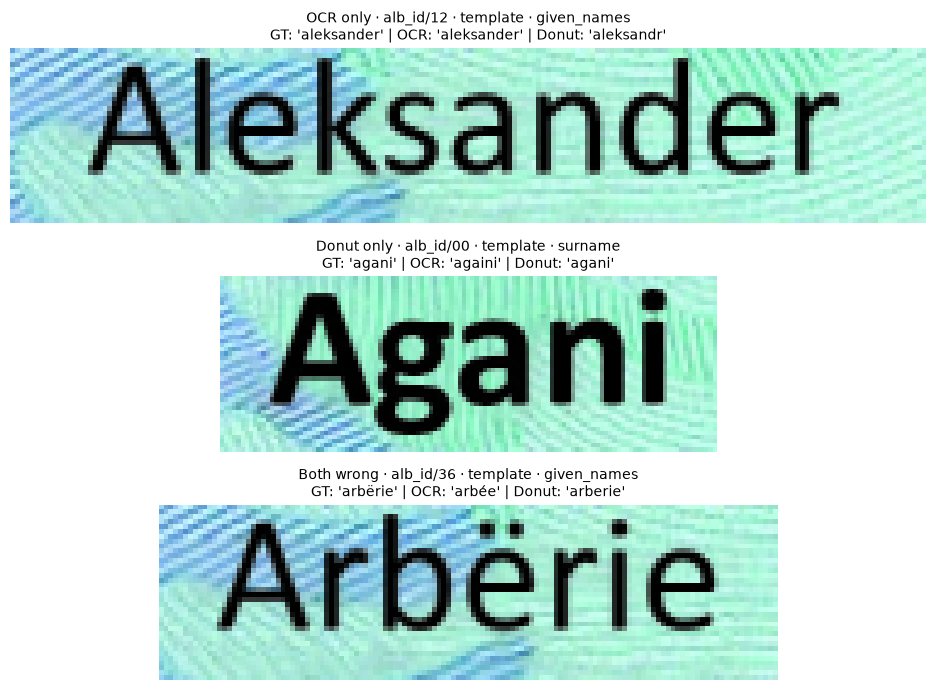

In [5]:
masks={
    'OCR only':pair.normalized_exact_match_ocr & ~pair.normalized_exact_match_donut,
    'Donut only':~pair.normalized_exact_match_ocr & pair.normalized_exact_match_donut,
    'Both wrong':~pair.normalized_exact_match_ocr & ~pair.normalized_exact_match_donut,
}
crop_policy=read_json(ROOT/'configs/ocr_pipeline_v1.json')['crop']
fig,axes=plt.subplots(3,1,figsize=(12,7))
gallery=[]
for axis,(category,mask) in zip(axes,masks.items()):
    row=pair.loc[mask].iloc[0]
    obs=obs_index[row.identity_key,row.source]
    crop,_=crop_field(obs['image'],obs['rectangles'][row.field],**crop_policy)
    axis.imshow(crop);axis.axis('off')
    axis.set_title(f"{category} · {row.identity_key} · {row.source} · {row.field}\n"
                   f"GT: {row.normalized_ground_truth_ocr!r} | OCR: {row.normalized_prediction_ocr!r} | Donut: {row.normalized_prediction_donut!r}",fontsize=10)
    gallery.append({'category':category,'identity_key':row.identity_key,'source':row.source,'field':row.field})
fig.tight_layout();fig.savefig(REVIEW/'failure_gallery.png',bbox_inches='tight');plt.show()
write_json(REVIEW/'gallery.json',gallery)

## 3. Understand the matched timing protocol

Both pipelines were measured in the same session, one resident model at a time.
Six blocks used order OCR, Donut, Donut, OCR, OCR, Donut: the middle repeat pair
reverses which model runs first. Each block warms three template and three photo
requests, then measures all 30 observations in a seeded shuffled order. Matching
repetition indices use the same observation permutation for each model.

That gives 90 measured requests per pipeline, 45 per source. Warm-ups, loading,
geometry, reference scoring, and writing are excluded. Full preprocessing,
encoder/decoder generation, decoding, parsing, normalization, and validation are
inside each request. GPU boundaries synchronize; no training feature cache is used.

These are warm local request measurements. Three repeats of the same documents
do not establish service tails, concurrency behavior, or universal hardware speed.

,pipeline,source,requests,inference_mean_ms,inference_median_ms,end_to_end_mean_ms,end_to_end_median_ms
0,donut,photo,45,498.740341,497.479989,511.684409,510.435164
1,donut,template,45,499.723349,500.084665,512.732238,512.949509
2,ocr,photo,45,293.338601,292.578442,301.334838,300.590031
3,ocr,template,45,294.992501,294.244257,303.004221,301.996489


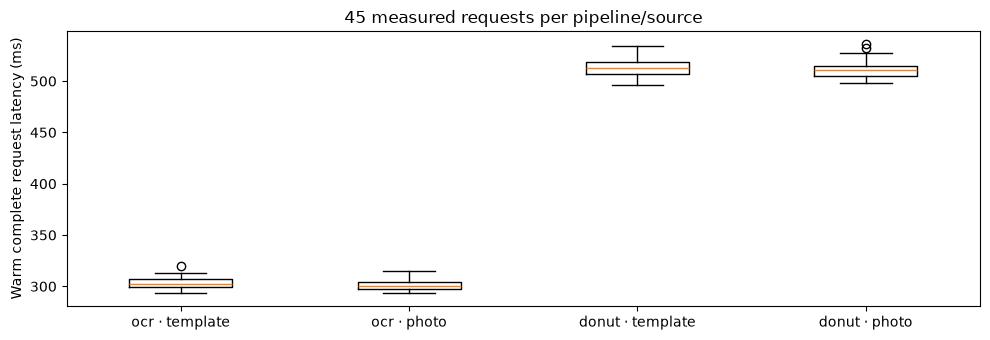

,block,pipeline,rss_mib,cuda_allocated_mib,cuda_reserved_mib,cuda_peak_allocated_mib,cuda_peak_reserved_mib
0,1,ocr,1802.164062,243.097656,272.0,255.260254,272.0
1,2,donut,1808.816406,779.729492,1298.0,1144.850586,1298.0
2,3,donut,1811.914062,779.729492,1298.0,1144.850586,1298.0
3,4,ocr,1829.738281,243.097656,272.0,255.260254,272.0
4,5,ocr,1834.257812,243.097656,272.0,255.260254,272.0
5,6,donut,1830.734375,779.729492,1298.0,1144.850586,1298.0


In [6]:
timings=pd.read_csv(COMPARISON/'timings.csv')
latency=pd.read_csv(COMPARISON/'latency_summary.csv')
assert len(timings)==180 and (latency.requests==45).all()
display(latency)
fig,axis=plt.subplots(figsize=(10,3.5))
labels=[];values=[]
for kind in ['ocr','donut']:
    for source in ['template','photo']:
        labels.append(f'{kind} · {source}')
        values.append(timings.loc[timings.pipeline.eq(kind)&timings.source.eq(source),'end_to_end_ms'].to_numpy())
axis.boxplot(values,tick_labels=labels,showfliers=True)
axis.set(ylabel='Warm complete request latency (ms)',title='45 measured requests per pipeline/source')
fig.tight_layout();fig.savefig(REVIEW/'latency_comparison.png',bbox_inches='tight');plt.show()
blocks=read_json(COMPARISON/'blocks.json')
display(pd.DataFrame([{'block':b['block'],'pipeline':b['pipeline'],**b['memory']} for b in blocks]))

## 4. Verify the reusable package boundary

`DonutPipeline.extract` takes one canonical RGB array. It accepts no identity,
reference values, field rectangles, or training-feature cache. A structural
failure retains raw tokens/text and returns missing canonical values; scoring
uses `raw_fields=None` to keep the failure denominator intact. Missing/extra keys
remain visible separately from semantic validity.

The retained verification compares every validation token sequence and raw field
mapping with both the independent research implementation and selected reload
records. Measured repeats also retained identical predictions. Verify the current
source hashes before interpreting those old checks as evidence for newer code.

In [7]:
source_hashes=read_json(COMPARISON/'source_hashes.json')
for name,digest in source_hashes.items():
    assert sha(ROOT/name)==digest,(name,'changed since measured comparison')
verified=read_json(COMPARISON/'donut_verification.json')
assert len(verified)==30 and completion['matching_raw_field_predictions']==210
for record in verified:
    result=record['result']
    assert parse_sequence(result['raw_sequence'])==research_parse(result['raw_sequence'])
    assert serialize_fields(obs_index[record['identity_key'],record['source']]['truth'])==research_serialize(obs_index[record['identity_key'],record['source']]['truth'])
print('Verified 30/30 token sequences, 210/210 raw field predictions, and 180/180 measured repeats.')
display(pd.Series({'pipeline_version':manifest['pipeline_version'],'checkpoint':manifest['checkpoint_relative_path'],
                   'selected_epoch':manifest['selection']['epoch'],'training_cache_in_inference':manifest['training_feature_cache_in_inference']}).to_frame('frozen path'))

Verified 30/30 token sequences, 210/210 raw field predictions, and 180/180 measured repeats.


,frozen path
pipeline_version,donut_v1
checkpoint,checkpoints/phase4_finetuning/20261015T1226577...
selected_epoch,10
training_cache_in_inference,False


### 4.1 Execute a real request using the frozen local model

The public loader checks artifact hashes, schema/vocabulary, preprocessing, and
token settings before inference. Missing weights are an explicit error rather
than a silent download or substitute checkpoint. Keep the manifest and exact
artifacts together when restoring this path on another machine.

Run one GPU request now, with only the canonical pixels as input. Its output must
match the retained validation sequence. This live check is outside the earlier
latency study and is not added to its 180-request distribution.

In [8]:
sample=observations[0]
pipeline=load_donut_pipeline(ROOT/'configs/donut_pipeline_v1.json',device='cuda:0')
live=pipeline.extract(sample['image'])
retained=next(r['result'] for r in verified if (r['identity_key'],r['source'])==(sample['identity_key'],sample['source']))
assert live['generated_token_ids']==retained['generated_token_ids']
assert live['fields']==retained['fields']
print('Live GPU request:',sample['identity_key'],sample['source'])
display(pd.Series(live['fields'],name='normalized extracted fields').to_frame())
print('Raw sequence:',repr(live['raw_sequence']))
print('Validation:',live['validation'])
del pipeline;gc.collect();torch.cuda.empty_cache()

Loading weights:   0%|          | 0/483 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 483/483 [00:00<00:00, 18064.07it/s]

Live GPU request: alb_id/00 template


,normalized extracted fields
document_number,367253746
surname,agani
given_names,adnan
date_of_birth,1991-11-20
expiry_date,2029-04-13
nationality,shqiptare/albanian
sex,M


Raw sequence: '<s_alb_id><s_document_number> 367253746</s_document_number><s_surname> agani</s_surname><s_given_names> adnan</s_given_names><s_date_of_birth> 1991-11-20</s_date_of_birth><s_expiry_date> 2029-04-13</s_expiry_date><s_nationality> shqiptare/albanian</s_nationality><s_sex> M</s_sex></s>'
Validation: {'is_valid': True, 'schema_is_valid': True, 'missing_fields': (), 'unexpected_fields': (), 'field_validations': {'document_number': {'is_valid': True, 'errors': ()}, 'surname': {'is_valid': True, 'errors': ()}, 'given_names': {'is_valid': True, 'errors': ()}, 'date_of_birth': {'is_valid': True, 'errors': ()}, 'expiry_date': {'is_valid': True, 'errors': ()}, 'nationality': {'is_valid': True, 'errors': ()}, 'sex': {'is_valid': True, 'errors': ()}}, 'document_errors': ()}


### 4.2 Explicit CPU smoke check

The loader accepts CPU explicitly; it does not silently fall back there. Execute
one CPU request on the same observation, compare tokens/fields, and save the
result. This checks one restoration/execution case, not a full CPU benchmark or
guaranteed cross-device token equality for every possible image.

In [9]:
cpu_pipeline=load_donut_pipeline(ROOT/'configs/donut_pipeline_v1.json',device='cpu')
cpu=cpu_pipeline.extract(sample['image'])
cpu_tokens_match=cpu['generated_token_ids']==live['generated_token_ids']
cpu_fields_match=cpu['fields']==live['fields']
print('CPU/GPU token parity:',cpu_tokens_match,'| normalized fields:',cpu_fields_match)
write_json(REVIEW/'cpu_smoke.json',{'identity_key':sample['identity_key'],'source':sample['source'],
                                  'tokens_match_gpu':cpu_tokens_match,'fields_match_gpu':cpu_fields_match,'cpu_result':cpu})
assert cpu_fields_match
del cpu_pipeline;gc.collect()
write_json(REVIEW/'review.json',{'comparison':str(COMPARISON.relative_to(ROOT)),
    'accuracy_replayed':True,'live_gpu_tokens_match':True,'cpu_fields_match_gpu':cpu_fields_match,
    'cpu_tokens_match_gpu':cpu_tokens_match,'test_evaluated':False})
print('Saved review:',REVIEW.relative_to(ROOT))

Loading weights:   0%|          | 0/483 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 483/483 [00:00<00:00, 19263.16it/s]

CPU/GPU token parity: True | normalized fields: True
Saved review: outputs/phase4_evaluation_review/20261015T124934943868Z


## 5. Interpret and hand off

The path is useful as a reproducible comparator even when it does not beat OCR.
Different field errors justify measuring the later benchmark; they do not prove
a router can identify the better route. A slower Donut path is a measured cost,
not a reason to hide negative results or retune on test.

The final [Phase 4 record](../docs/phases/phase-4.md) links the adopted manifest,
source, tests, notebooks, reports, and remaining limitations. Phase 5 receives
two frozen extraction paths. It will study controlled degradations and pipeline
complementarity; model selection does not reopen after seeing final test results.

## Reflection and exercises

1. Explain the difference between Field EM, Document EM, and CER using the actual
   counts above. Which fields improve and which regress relative to OCR?
2. Why are the four-way field counts not a document-routing oracle? What would
   an online router need to observe, and which information is forbidden?
3. Draw both timing boundaries. Where are image loading, rectification, decoder
   KV cache, training feature cache, parsing, and semantic validation accounted for?
4. Why do exact saved tokens and source hashes matter when extracting notebook
   code into a package? What do unit tests cover that a successful model request does not?
5. Why is a well-formed seven-field mapping insufficient evidence for operational KYC safety?

**Exercise A:** inspect one both-wrong example and propose a research question
without changing its reference, adding a correction map, or inspecting test data.

**Exercise B:** compare latency means and medians from retained records. Explain
what additional workload/protocol would be required to make a p99 service claim.

**Exercise C:** restore the exact checkpoint into a separate artifact root and
call `load_donut_pipeline(..., artifact_root=...)`. Try a missing/corrupt file
and predict whether failure occurs before any model loader is invoked.